# Did the nervous system already reduce the dimensions? Pose synergies vs muscle synergies

The pose of the hand is low-dimensional (a few PCs describe it well), and a decoder only reads a few of those
directions out of the wrist EMG (`compression_tolerance.ipynb`). A neuroscience question follows: **is the
low-dimensional structure already present in the muscle signal, as if the nervous system controlled the hand
through a few shared commands (synergies)?** Or is it something the decoder or the hand's mechanics impose?

This is an old debate in motor control: are synergies a **neural** strategy to simplify control, or a by-product of
**task and biomechanical constraints** (Tresch & Jarc 2009; Kutch & Valero-Cuevas 2012)? We cannot settle it with one
person and 16 surface electrodes. The goal here is to **explore** and to **design the tests** that the full dataset
(193 people) could run. Each section states a hypothesis, a test, the result on the mini dataset, and what would
count as evidence against it.

| | hypothesis | test here |
|---|---|---|
| H1 | muscle activity is low-dimensional **beyond what electrode crosstalk explains** | dimension of envelope co-modulation vs the array's spatial resolution |
| H2 | the EMG → pose mapping is **low-rank** (a “communication subspace”) | reduced-rank regression |
| H3 | the decodable pose directions are the **same** as the pose synergies (PCs) | principal angles between subspaces |
| H4 | a few muscle synergies carry **all** the pose information the EMG has | decoding from 5 NMF activations vs 16 channels |
| H5 | muscle synergies are **shared** across tasks and across hands | held-out-task VAF, left vs right synergies |

Data: mini dataset (1 held-out user), both hands, `unconstrained` excluded. Everything at 50 Hz.

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/rodri/projects/emg2poseneuromatch/semg2pose/.venv/bin/python


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.linalg import subspace_angles
from scipy.optimize import linear_sum_assignment, nnls
from sklearn.decomposition import NMF

from semg2pose.data import FS, JOINT_NAMES, download_mini_dataset, list_sessions, load_session
from semg2pose.signals import bandpass, log_envelope, rms_envelope

warnings.filterwarnings("ignore")
DATASET_DIR = download_mini_dataset()
plt.rcParams["figure.dpi"] = 100
STEP = 40           # 2 kHz -> 50 Hz
FS_L = FS // STEP
LAGS = [0, 2, 5, 10, 15]   # 0-300 ms of EMG history, in 50 Hz samples
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9AA1B0"

Dataset already downloaded: /home/rodri/emg2pose_dataset_mini


## 1. Data

Per recording: log-envelope (20-450 Hz, 50 ms RMS) and linear envelope (for NMF) of the 16 channels, the 20 joint
angles, and the raw 120-250 Hz band-passed EMG (used in section 2 to measure crosstalk).

In [3]:
sessions = list_sessions(DATASET_DIR)
recs, raw_corr = [], []
for _, row in sessions.iterrows():
    if row.stage == "unconstrained":
        continue
    emg, angles, ok, meta = load_session(row.path)
    good = ~np.convolve(~ok, np.ones(601), mode="same").astype(bool)[::STEP]
    recs.append({"stage": row.stage, "side": row.side,
                 "env": log_envelope(emg, band=(20, 450), window_s=0.05)[::STEP],
                 "lin": rms_envelope(bandpass(emg, 20, 450), window_s=0.1)[::STEP],
                 "ang": np.degrees(angles[::STEP]),
                 "vel": np.degrees(signal.savgol_filter(angles, 301, 3, deriv=1, delta=1 / FS, axis=0)[::STEP]),
                 "ok": good})
    raw_corr.append(np.corrcoef(bandpass(emg, 120, 250).T))
print(f"{len(recs)} recordings, {sum(r['ok'].sum() for r in recs) / FS_L / 60:.1f} valid minutes")

28 recordings, 24.7 valid minutes


## 2. H1: is the muscle activity low-dimensional beyond crosstalk?

A trap first. Neighbouring electrodes see partly the same motor units (volume conduction, `motor_units_zoom.ipynb`
§8.4), so the 16 channels are correlated **even if every muscle were controlled independently**. Low dimensionality
of the EMG alone proves nothing.

**Idea.** Measure two dimensions with the same yardstick (participation ratio of a correlation matrix):

- **Spatial resolution of the array**: correlation between channels of the *raw* 120-250 Hz signal. Individual motor
  unit spikes are fast and unsynchronised, so raw-signal correlation between two electrodes mostly reflects shared
  *sources* (crosstalk), not shared *commands*. Its dimension ≈ how many independent spatial “views” the array has.
- **Co-modulation of activity**: correlation between the *envelopes*. If different muscles are driven by shared
  commands, their activity levels rise and fall together, so the envelopes are lower-dimensional than the raw signal.

H1 predicts dimension(envelopes) clearly below dimension(raw). If both were equal, the low dimensionality of the EMG
would be explained by crosstalk alone.

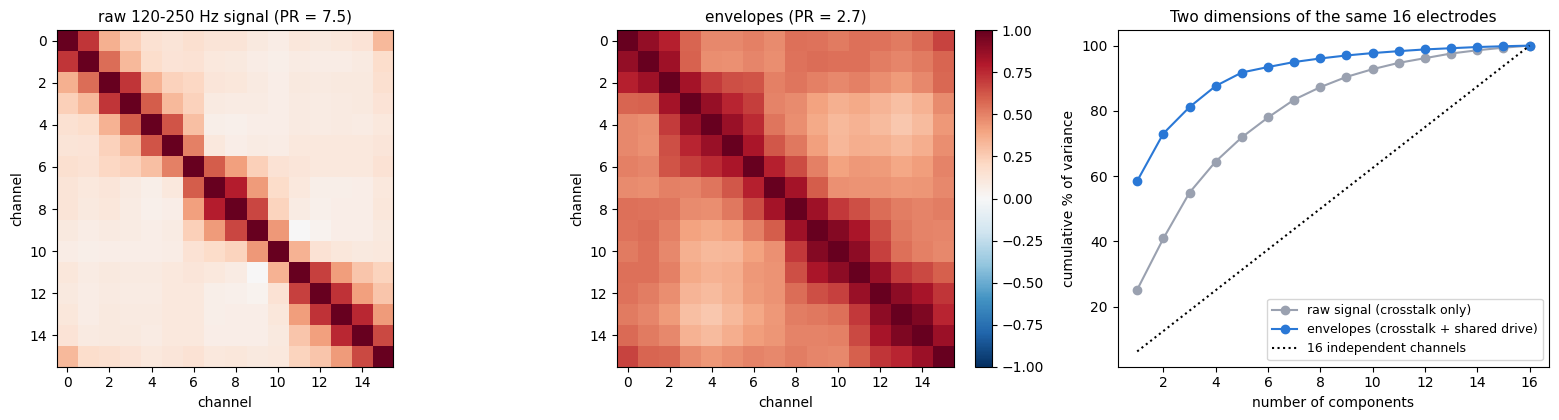

participation ratio: raw signal 7.5, envelopes 2.7 (16 = independent channels)


In [4]:
def participation_ratio(C):
    ev = np.clip(np.linalg.eigvalsh(C), 0, None)
    return ev.sum() ** 2 / (ev ** 2).sum(), np.sort(ev)[::-1] / ev.sum()


C_raw = np.mean(raw_corr, axis=0)
C_env = np.mean([np.corrcoef(r["env"][r["ok"]].T) for r in recs], axis=0)
C_env_resid = np.mean([np.corrcoef((r["env"][r["ok"]] - r["env"][r["ok"]].mean(0)).T) for r in recs], axis=0)
pr_raw, ev_raw = participation_ratio(C_raw)
pr_env, ev_env = participation_ratio(C_env)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, C, title in [(ax1, C_raw, f"raw 120-250 Hz signal (PR = {pr_raw:.1f})"), (ax2, C_env, f"envelopes (PR = {pr_env:.1f})")]:
    im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1); ax.set_title(title, fontsize=11)
    ax.set_xlabel("channel"); ax.set_ylabel("channel")
plt.colorbar(im, ax=ax2, fraction=0.046)
ax3.plot(range(1, 17), 100 * np.cumsum(ev_raw), "o-", color=GREY, label="raw signal (crosstalk only)")
ax3.plot(range(1, 17), 100 * np.cumsum(ev_env), "o-", color=BLUE, label="envelopes (crosstalk + shared drive)")
ax3.plot(range(1, 17), 100 * np.arange(1, 17) / 16, ":", color="k", label="16 independent channels")
ax3.set_xlabel("number of components"); ax3.set_ylabel("cumulative % of variance"); ax3.legend(fontsize=9)
ax3.set_title("Two dimensions of the same 16 electrodes", fontsize=11)
plt.tight_layout(); plt.show()
print(f"participation ratio: raw signal {pr_raw:.1f}, envelopes {pr_env:.1f} (16 = independent channels)")

## 3. H2: is the EMG → pose mapping low-rank? (a communication subspace)

**Method: reduced-rank regression (RRR).** A normal linear decoder maps 80 EMG features (16 channels × 5 lags) to 20
angles with a full 80 × 20 matrix. RRR forces that matrix to have rank r: the EMG can only talk to the pose through r
channels. This is the method Semedo et al. (2019) used to show that two cortical areas interact through a
low-dimensional “communication subspace”. If rank 3-4 already reaches almost the full performance, the useful
EMG → pose information flows through a few dimensions.

Evaluation: blocked 5-fold CV within each recording, R² pooled over the 20 angles (variance-weighted, in degrees).
We also compare with the **project's PCA bottleneck**: predict only the first r pose PCs (an unsupervised choice of
the r directions) instead of the r directions that RRR picks using the EMG.

X (74227, 80) Y (74227, 20)


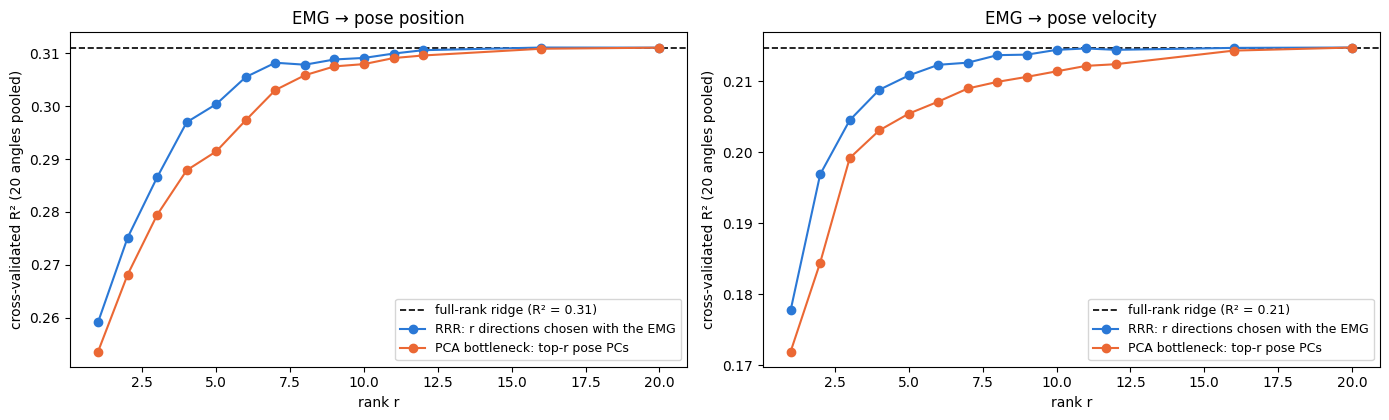

position : full R² 0.311; rank for 90 % of it: RRR 3, PCA bottleneck 4
velocity : full R² 0.215; rank for 90 % of it: RRR 2, PCA bottleneck 3


In [5]:
def lagged(X, lags=LAGS):
    return np.hstack([X if l == 0 else np.vstack([np.repeat(X[:1], l, axis=0), X[:-l]]) for l in lags])


Xs, Ys, Vs, Fs, Ss, Hs = [], [], [], [], [], []
for r in recs:
    T = len(r["ok"]); keep = r["ok"]
    Xs.append(lagged(r["env"])[keep]); Ys.append(r["ang"][keep]); Vs.append(r["vel"][keep])
    Fs.append((np.arange(T) * 5 // T)[keep]); Ss.append(np.full(keep.sum(), r["stage"])); Hs.append(np.full(keep.sum(), r["side"]))
X, Y, V, folds, stage_lab, side_lab = map(np.concatenate, (Xs, Ys, Vs, Fs, Ss, Hs))
X, Y, V = np.vstack(Xs), np.vstack(Ys), np.vstack(Vs)
# Null input used as a control below: each recording's EMG features shifted by half the recording relative to its pose,
# which destroys the moment-to-moment EMG-pose link but keeps each recording's EMG statistics.
Xn, _start = [], 0
for r in recs:
    _n = r["ok"].sum(); Xn.append(np.roll(X[_start:_start + _n], _n // 2, axis=0)); _start += _n
Xn = np.vstack(Xn)
print("X", X.shape, "Y", Y.shape)


def rrr_cv(X, Y, folds, ranks, lam=10.0, mode="rrr"):
    """R² (pooled over outputs) for each rank. mode='rrr': supervised directions; 'pca': top-r PCs of the training Y."""
    preds = {r: np.zeros_like(Y) for r in ranks}
    full = np.zeros_like(Y)
    for k in range(5):
        tr, te = folds != k, folds == k
        mx, sx, my = X[tr].mean(0), X[tr].std(0) + 1e-9, Y[tr].mean(0)
        A, B = (X[tr] - mx) / sx, (X[te] - mx) / sx
        W = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (Y[tr] - my))
        full[te] = B @ W + my
        if mode == "rrr":
            _, _, Vt = np.linalg.svd(A @ W, full_matrices=False)       # directions of the fitted values
        else:
            _, _, Vt = np.linalg.svd(Y[tr] - my, full_matrices=False)  # pose PCs of the training data
        for r in ranks:
            P = Vt[:r].T @ Vt[:r]
            preds[r][te] = (B @ W) @ P + my
    r2 = lambda Pr: 1 - ((Y - Pr) ** 2).sum() / ((Y - Y.mean(0)) ** 2).sum()
    return {r: r2(p) for r, p in preds.items()}, r2(full)


RANKS = list(range(1, 13)) + [16, 20]
res = {}
for target, Yt in [("position", Y), ("velocity", V)]:
    rr, full = rrr_cv(X, Yt, folds, RANKS, mode="rrr")
    pc, _ = rrr_cv(X, Yt, folds, RANKS, mode="pca")
    res[target] = (rr, pc, full)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, (target, (rr, pc, full)) in zip(axs, res.items()):
    ax.axhline(full, color="k", ls="--", lw=1.2, label=f"full-rank ridge (R² = {full:.2f})")
    ax.plot(RANKS, [rr[r] for r in RANKS], "o-", color=BLUE, label="RRR: r directions chosen with the EMG")
    ax.plot(RANKS, [pc[r] for r in RANKS], "o-", color=ORANGE, label="PCA bottleneck: top-r pose PCs")
    ax.set_xlabel("rank r"); ax.set_ylabel("cross-validated R² (20 angles pooled)"); ax.set_title(f"EMG → pose {target}")
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()
for target, (rr, pc, full) in res.items():
    r90 = next(r for r in RANKS if rr[r] >= 0.9 * full)
    p90 = next(r for r in RANKS if pc[r] >= 0.9 * full)
    print(f"{target:9s}: full R² {full:.3f}; rank for 90 % of it: RRR {r90}, PCA bottleneck {p90}")

**A control that changes the reading.** R² pooled over angles in degrees is dominated by PC1 (more than half of the
pose variance), so “rank 3 is enough” partly says “PC1 dominates the degree scale”. Two checks: (a) give the first 8
pose PCs **equal weight** (z-score their scores) and ask again how many dimensions are needed; (b) the same with the
**null input**.

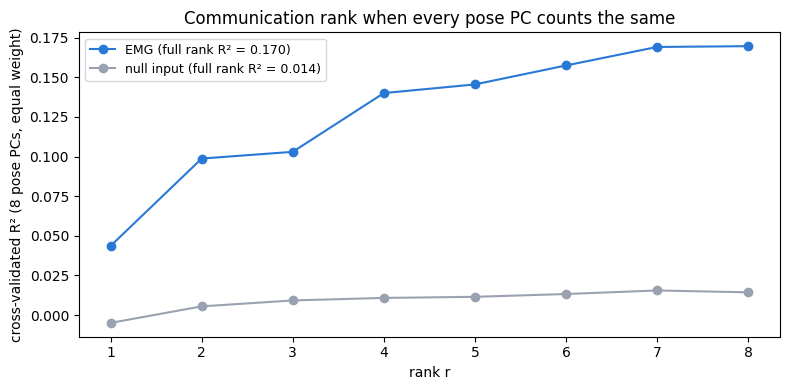

equal weight: full R² 0.170 (null 0.014); rank for 90 %: 6 of 8


In [6]:
_, _, Vt_pose = np.linalg.svd(Y - Y.mean(0), full_matrices=False)
Zeq = (Y - Y.mean(0)) @ Vt_pose[:8].T
Zeq = Zeq / Zeq.std(0)
R8 = list(range(1, 9))
eq = {}
for name, Xi in [("EMG", X), ("null input", Xn)]:
    rr_eq, full_eq = rrr_cv(Xi, Zeq, folds, R8, mode="rrr")
    eq[name] = (rr_eq, full_eq)
fig, ax = plt.subplots(figsize=(8, 4))
for name, col in [("EMG", BLUE), ("null input", GREY)]:
    rr_eq, full_eq = eq[name]
    ax.plot(R8, [rr_eq[r] for r in R8], "o-", color=col, label=f"{name} (full rank R² = {full_eq:.3f})")
ax.set_xlabel("rank r"); ax.set_ylabel("cross-validated R² (8 pose PCs, equal weight)"); ax.legend(fontsize=9)
ax.set_title("Communication rank when every pose PC counts the same")
plt.tight_layout(); plt.show()
rr_eq, full_eq = eq["EMG"]
r90_eq = next(r for r in R8 if rr_eq[r] >= 0.9 * full_eq)
print(f"equal weight: full R² {full_eq:.3f} (null {eq['null input'][1]:.3f}); rank for 90 %: {r90_eq} of 8")

**Reading it.** The decoding itself is real (R² far above the null). But with equal weights the EMG needs about 6 of
the 8 PC dimensions to reach 90 % of its performance. So “rank 3” holds **for the benchmark's metric** (errors in
degrees, where PC1 dominates), which is what matters for choosing k in the project. It does **not** support the neural
claim that the EMG talks to the hand through a 3-D channel: the weaker pose directions are each decoded a little.

## 4. H3: are the decodable directions the pose synergies?

RRR picks the r pose directions that the EMG predicts best. PCA picks the r directions in which the pose varies most.
If they coincide, a PCA bottleneck already sits on the decodable subspace. We measure the overlap between the two
r-dimensional subspaces of the 20-D pose space (mean cos² of the principal angles: 1 = identical, r/20 = random), and
show which pose PCs the RRR directions are made of.

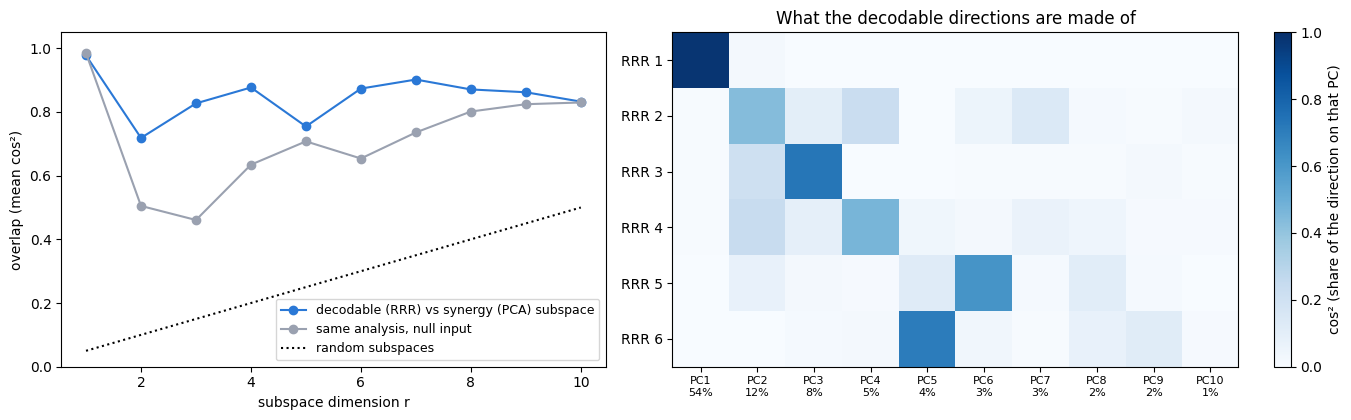

overlap: {1: 0.98, 2: 0.72, 3: 0.83, 4: 0.88, 5: 0.75, 6: 0.87, 7: 0.9, 8: 0.87, 9: 0.86, 10: 0.83}
null   : {1: 0.98, 2: 0.5, 3: 0.46, 4: 0.63, 5: 0.71, 6: 0.65, 7: 0.74, 8: 0.8, 9: 0.82, 10: 0.83}


In [7]:
mx, sx, my = X.mean(0), X.std(0) + 1e-9, Y.mean(0)
A = (X - mx) / sx
W = np.linalg.solve(A.T @ A + 10 * np.eye(A.shape[1]), A.T @ (Y - my))
_, _, Vt_rrr = np.linalg.svd(A @ W, full_matrices=False)
_, s_pose, Vt_pca = np.linalg.svd(Y - my, full_matrices=False)
ev_pose = s_pose ** 2 / (s_pose ** 2).sum()
overlap = {r: np.mean(np.cos(subspace_angles(Vt_rrr[:r].T, Vt_pca[:r].T)) ** 2) for r in range(1, 11)}
An = (Xn - Xn.mean(0)) / (Xn.std(0) + 1e-9)
Wn = np.linalg.solve(An.T @ An + 10 * np.eye(An.shape[1]), An.T @ (Y - my))
_, _, Vt_null = np.linalg.svd(An @ Wn, full_matrices=False)
overlap_null = {r: np.mean(np.cos(subspace_angles(Vt_null[:r].T, Vt_pca[:r].T)) ** 2) for r in range(1, 11)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1, 1.3]})
ax1.plot(list(overlap), list(overlap.values()), "o-", color=BLUE, label="decodable (RRR) vs synergy (PCA) subspace")
ax1.plot(list(overlap_null), list(overlap_null.values()), "o-", color=GREY, label="same analysis, null input")
ax1.plot(list(overlap), [r / 20 for r in overlap], ":", color="k", label="random subspaces")
ax1.set_xlabel("subspace dimension r"); ax1.set_ylabel("overlap (mean cos²)"); ax1.set_ylim(0, 1.05); ax1.legend(fontsize=9)
M = np.abs(Vt_rrr[:6] @ Vt_pca[:10].T) ** 2          # how much of each RRR direction lies on each pose PC
im = ax2.imshow(M, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax2.set_xticks(range(10), [f"PC{i + 1}\n{100 * ev_pose[i]:.0f}%" for i in range(10)], fontsize=8)
ax2.set_yticks(range(6), [f"RRR {i + 1}" for i in range(6)])
plt.colorbar(im, ax=ax2, label="cos² (share of the direction on that PC)")
ax2.set_title("What the decodable directions are made of")
plt.tight_layout(); plt.show()
print("overlap:", {r: round(v, 2) for r, v in overlap.items()})
print("null   :", {r: round(v, 2) for r, v in overlap_null.items()})

**Reading it: this test is not informative as it stands.** The directions found by a regression in degree units are
pulled towards the high-variance pose directions whatever the input, so the null input (EMG with no moment-to-moment
link to the pose) already overlaps 0.98 at r = 1 and 0.5-0.8 beyond. The real EMG is only modestly above that
(differences of ~0.1-0.4 at r = 2-6). The cleaner evidence about *which* pose directions the EMG sees is the per-PC
decoding in section 5 (PC1 strongly, the others weakly). A proper version of H3 needs whitened pose units and a null
distribution (several shifts), as done in `network_internals.ipynb`.

## 5. H4: do a few muscle synergies carry all the pose information?

**Muscle synergies** (NMF on the envelopes, as in `emg_kinematics_encoding.ipynb` §6): EMG(t) ≈ Σ_k c_k(t) w_k with
non-negative spatial patterns w_k. If the nervous system drives the hand through ~5 commands, then the 5 activations
c_k(t) should predict the pose about as well as all 16 channels. We decode the pose from (a) 16 channels and (b) the
5 NMF activations, same lags, same CV.

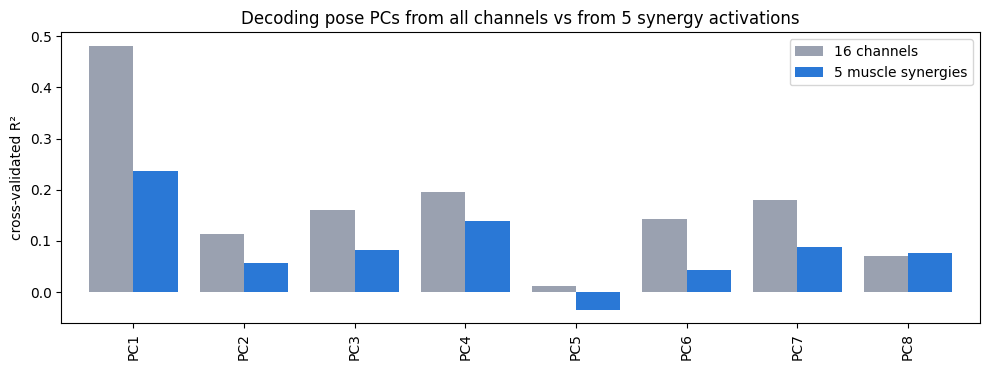

                     PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8
16 channels         0.48  0.11  0.16  0.20  0.01  0.14  0.18  0.07
5 muscle synergies  0.24  0.06  0.08  0.14 -0.03  0.04  0.09  0.08
variance-weighted: 16 ch 0.338, 5 synergies 0.166


In [8]:
Lin = np.vstack([r["lin"][r["ok"]] for r in recs])
scale_ch = Lin.std(0)
nmf = NMF(n_components=5, init="nndsvda", max_iter=800, random_state=0).fit(Lin / scale_ch)
Wsyn = nmf.components_
acts = []
for r in recs:
    Cr = nmf.transform(r["lin"] / scale_ch)
    acts.append(lagged(np.log1p(Cr))[r["ok"]])
Xsyn = np.vstack(acts)


def ridge_r2(X, Y, folds, lam=10.0):
    P = np.zeros_like(Y)
    for k in range(5):
        tr, te = folds != k, folds == k
        mx, sx, my = X[tr].mean(0), X[tr].std(0) + 1e-9, Y[tr].mean(0)
        A, B = (X[tr] - mx) / sx, (X[te] - mx) / sx
        P[te] = B @ np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (Y[tr] - my)) + my
    return 1 - ((Y - P) ** 2).sum(0) / ((Y - Y.mean(0)) ** 2).sum(0)


Z = (Y - my) @ Vt_pca[:8].T           # pose PC scores (positions)
dec = pd.DataFrame({"16 channels": ridge_r2(X, Z, folds), "5 muscle synergies": ridge_r2(Xsyn, Z, folds)},
                   index=[f"PC{i + 1}" for i in range(8)])
ax = dec.plot.bar(figsize=(10, 3.8), color=[GREY, BLUE], width=0.8)
ax.set_ylabel("cross-validated R²"); ax.set_title("Decoding pose PCs from all channels vs from 5 synergy activations")
plt.tight_layout(); plt.show()
print(dec.round(2).T)
print(f"variance-weighted: 16 ch {np.average(dec['16 channels'], weights=ev_pose[:8]):.3f}, "
      f"5 synergies {np.average(dec['5 muscle synergies'], weights=ev_pose[:8]):.3f}")

**H4 fails, and that is informative.** Five synergies explain ~90 % of the EMG variance, yet they keep only about
half of the pose information the 16 channels have. So the structure that dominates the muscle signal is not the
whole story for the pose. One candidate explanation is **co-contraction**: flexors and extensors activating together
to stiffen the hand, which produces EMG and moves nothing. The next section tests it.

## 5b. Pose-potent and pose-null muscle activity

In motor cortex, Kaufman et al. (2014) split population activity into **output-potent** directions (which drive the
muscles) and **output-null** directions (activity that cancels out, e.g. during movement preparation). The same idea
one level down: split the 16-D envelope space into the few directions the linear EMG → pose map reads
(**pose-potent**, from the rank-3 RRR map at lag 0) and the rest (**pose-null**). Then ask how much of the EMG
variance lives in each, and how the potent directions compare with the high-variance EMG directions (EMG PCs).

EMG variance in the 3 pose-potent directions: 7 % (the 3 highest-variance EMG directions hold 84 %; random 3-D subspace: 19 %)
overlap pose-potent vs top-3 EMG PCs: 0.09 (random: 0.19)


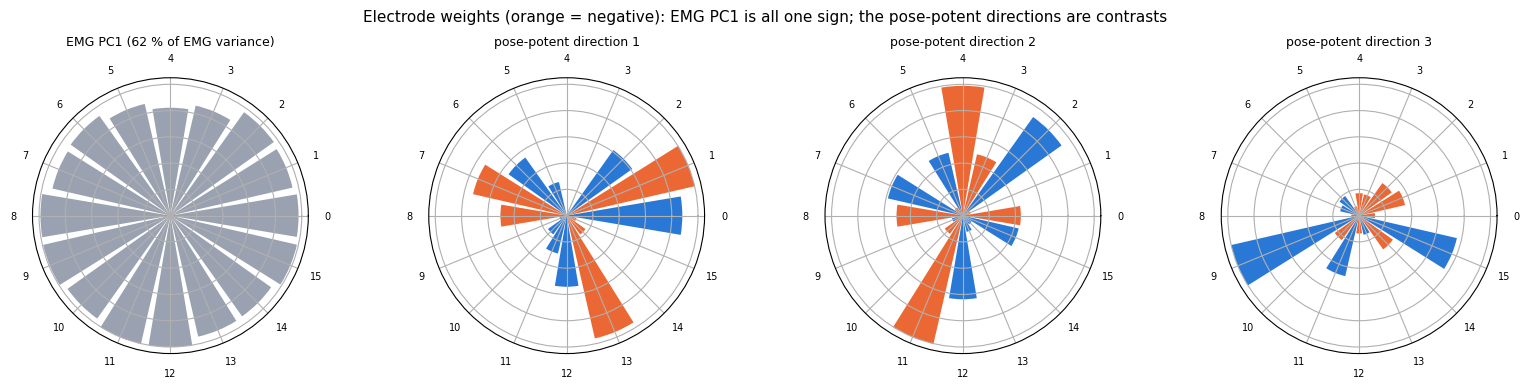

In [9]:
E0 = np.vstack([r["env"][r["ok"]] for r in recs])
Ez = (E0 - E0.mean(0)) / E0.std(0)
W0 = np.linalg.solve(Ez.T @ Ez + 10 * np.eye(16), Ez.T @ (Y - my))           # 16 x 20, lag 0
_, _, Vr = np.linalg.svd(Ez @ W0, full_matrices=False)
R_POT = 3
W0r = W0 @ Vr[:R_POT].T @ Vr[:R_POT]                                         # rank-3 map
U_pot = np.linalg.svd(W0r, full_matrices=False)[0][:, :R_POT]               # pose-potent input directions (16 x 3)
Cx = np.cov(Ez.T)
ev_x, U_x = np.linalg.eigh(Cx); ev_x, U_x = ev_x[::-1], U_x[:, ::-1]
frac_pot = np.trace(U_pot.T @ Cx @ U_pot) / np.trace(Cx)
frac_top = ev_x[:R_POT].sum() / ev_x.sum()
ov = np.mean(np.cos(subspace_angles(U_pot, U_x[:, :R_POT])) ** 2)
print(f"EMG variance in the 3 pose-potent directions: {100 * frac_pot:.0f} % "
      f"(the 3 highest-variance EMG directions hold {100 * frac_top:.0f} %; random 3-D subspace: {100 * 3 / 16:.0f} %)")
print(f"overlap pose-potent vs top-3 EMG PCs: {ov:.2f} (random: {3 / 16:.2f})")

pc1 = U_x[:, 0] * np.sign(U_x[:, 0].sum())
fig, axs = plt.subplots(1, 1 + R_POT, figsize=(16, 3.8), subplot_kw={"projection": "polar"})
for ax, w, title, col in [(axs[0], pc1, f"EMG PC1 ({100 * ev_x[0] / ev_x.sum():.0f} % of EMG variance)", GREY)] + \
        [(axs[k + 1], U_pot[:, k], f"pose-potent direction {k + 1}", BLUE) for k in range(R_POT)]:
    w = w / np.abs(w).max()
    ax.bar(ang_c := 2 * np.pi * np.arange(16) / 16, np.abs(w), width=2 * np.pi / 16 * 0.85, color=np.where(w > 0, col, ORANGE))
    ax.set_xticks(ang_c, [str(c) for c in range(16)], fontsize=7); ax.set_yticklabels([]); ax.set_title(title, fontsize=9)
fig.suptitle("Electrode weights (orange = negative): EMG PC1 is all one sign; the pose-potent directions are contrasts", fontsize=11)
plt.tight_layout(); plt.show()

**A caveat and a cross-check.** Decoder weights are biased towards low-variance directions by construction (a
regression divides by the input covariance), so the 7 % above may overstate the effect. The unbiased check goes the
other way round (encoding): predict each EMG principal component from the kinematics (20 angles and their
velocities split by direction, 60 ms later) and see which EMG components the movement explains.

In [10]:
Kin = []
for r in recs:
    T = len(r["ok"]); t = np.arange(T - 3)
    kin = np.hstack([r["ang"], np.clip(r["vel"], 0, None), np.clip(-r["vel"], 0, None)])
    Kin.append((kin[t + 3], r["env"][t], (r["ok"][t] & r["ok"][t + 3]), (t * 5 // T)))
Kx = np.vstack([k[0][k[2]] for k in Kin]); Ke = np.vstack([k[1][k[2]] for k in Kin]); Kf = np.concatenate([k[3][k[2]] for k in Kin])
Kez = (Ke - E0.mean(0)) / E0.std(0)
scores = Kez @ U_x[:, :6]                                     # EMG PC scores
r2_pc = ridge_r2(Kx, scores, Kf)
enc = pd.DataFrame({"% of EMG variance": 100 * ev_x[:6] / ev_x.sum(), "R² from kinematics": r2_pc},
                   index=[f"EMG PC{i + 1}" for i in range(6)])
print(enc.round(2))
print(f"EMG variance explained by kinematics overall: {100 * np.dot(ev_x[:6] / ev_x.sum(), r2_pc):.0f} % "
      f"(first 6 EMG PCs, which hold {100 * ev_x[:6].sum() / ev_x.sum():.0f} % of the variance)")

         % of EMG variance  R² from kinematics
EMG PC1              61.56                0.26
EMG PC2              14.10                0.29
EMG PC3               8.07                0.19
EMG PC4               5.43                0.21
EMG PC5               3.58                0.19
EMG PC6               1.52                0.06
EMG variance explained by kinematics overall: 24 % (first 6 EMG PCs, which hold 94 % of the variance)


**Reading it.**

- EMG PC1 (~60 % of the variance) has the same sign on every electrode: everything up or down together, i.e.
  overall effort. The decoder's pose-potent directions are **contrasts** between sectors (the flexor/extensor
  balance).
- But the encoding cross-check does **not** support “PC1 is pose-null co-contraction”: the kinematics explain about
  the same fraction (R² ≈ 0.2-0.3) of every EMG component, PC1 included. The tiny 7 % comes mostly from the
  decoder-weight bias. What does hold: **only about a quarter of the envelope variance is explained by finger
  kinematics**, spread over all EMG components. The other three quarters are co-contraction, wrist activity (not in
  the labels), force without movement, and noise, and this data cannot separate them.
- A clean test of the co-contraction idea needs conditions where stiffness changes without movement (isometric
  holds, grasping objects of different weight), which emg2pose does not label. Worth keeping as an open question, not
  as a result.

## 6. H5: are muscle synergies shared across tasks and across hands?

Synergies of neural origin should be a fixed vocabulary reused across tasks. Synergies imposed by each task should
change from task to task.

- **Across tasks**: fit 5 synergies on all tasks but one, then explain the held-out task with them (activations
  fitted by non-negative least squares, spatial patterns fixed). Compare the variance accounted for (VAF) with
  synergies fitted on that task itself.
- **Across hands**: fit 4 synergies on each hand separately (the paper says the electrode indices line up with the
  same anatomy on both hands) and match them. Similar synergies on both hands are consistent with a shared
  anatomical or neural organisation, though they cannot tell the two apart.

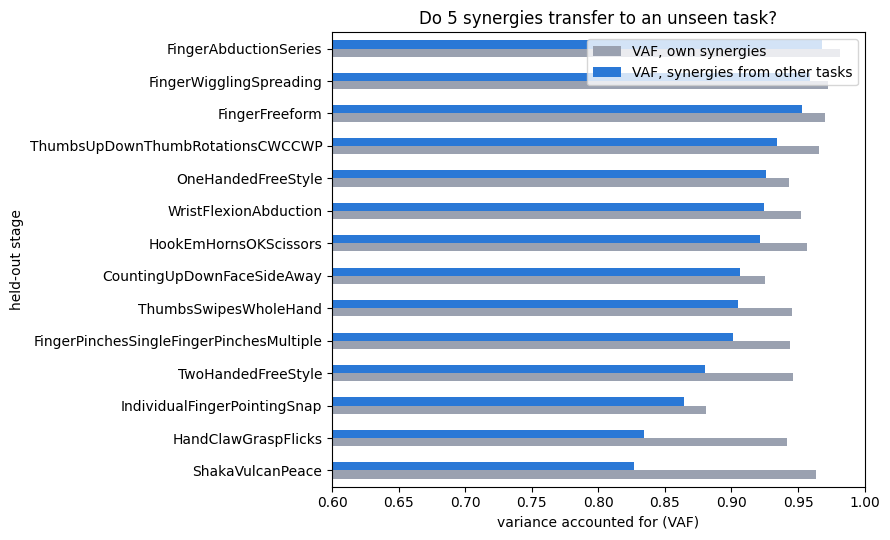

VAF, own synergies                 0.949
VAF, synergies from other tasks    0.907


In [11]:
def vaf(E, Wt):
    H = np.array([nnls(Wt.T, e)[0] for e in E])
    return 1 - ((E - H @ Wt) ** 2).sum() / (E ** 2).sum()


rows = []
stages = sorted({r["stage"] for r in recs})
for st in stages:
    E_tr = np.vstack([r["lin"][r["ok"]] for r in recs if r["stage"] != st]) / scale_ch
    E_te = np.vstack([r["lin"][r["ok"]] for r in recs if r["stage"] == st]) / scale_ch
    E_te = E_te[::4]                                   # 12.5 Hz is enough for VAF and keeps NNLS fast
    W_other = NMF(n_components=5, init="nndsvda", max_iter=600, random_state=0).fit(E_tr[::2]).components_
    W_self = NMF(n_components=5, init="nndsvda", max_iter=600, random_state=0).fit(E_te).components_
    rows.append({"held-out stage": st, "VAF, own synergies": vaf(E_te, W_self), "VAF, synergies from other tasks": vaf(E_te, W_other)})
cross = pd.DataFrame(rows).set_index("held-out stage")
ax = cross.sort_values("VAF, synergies from other tasks").plot.barh(figsize=(9, 5.5), color=[GREY, BLUE])
ax.set_xlim(0.6, 1); ax.set_xlabel("variance accounted for (VAF)"); ax.set_title("Do 5 synergies transfer to an unseen task?")
plt.tight_layout(); plt.show()
print(cross.mean().round(3).to_string())

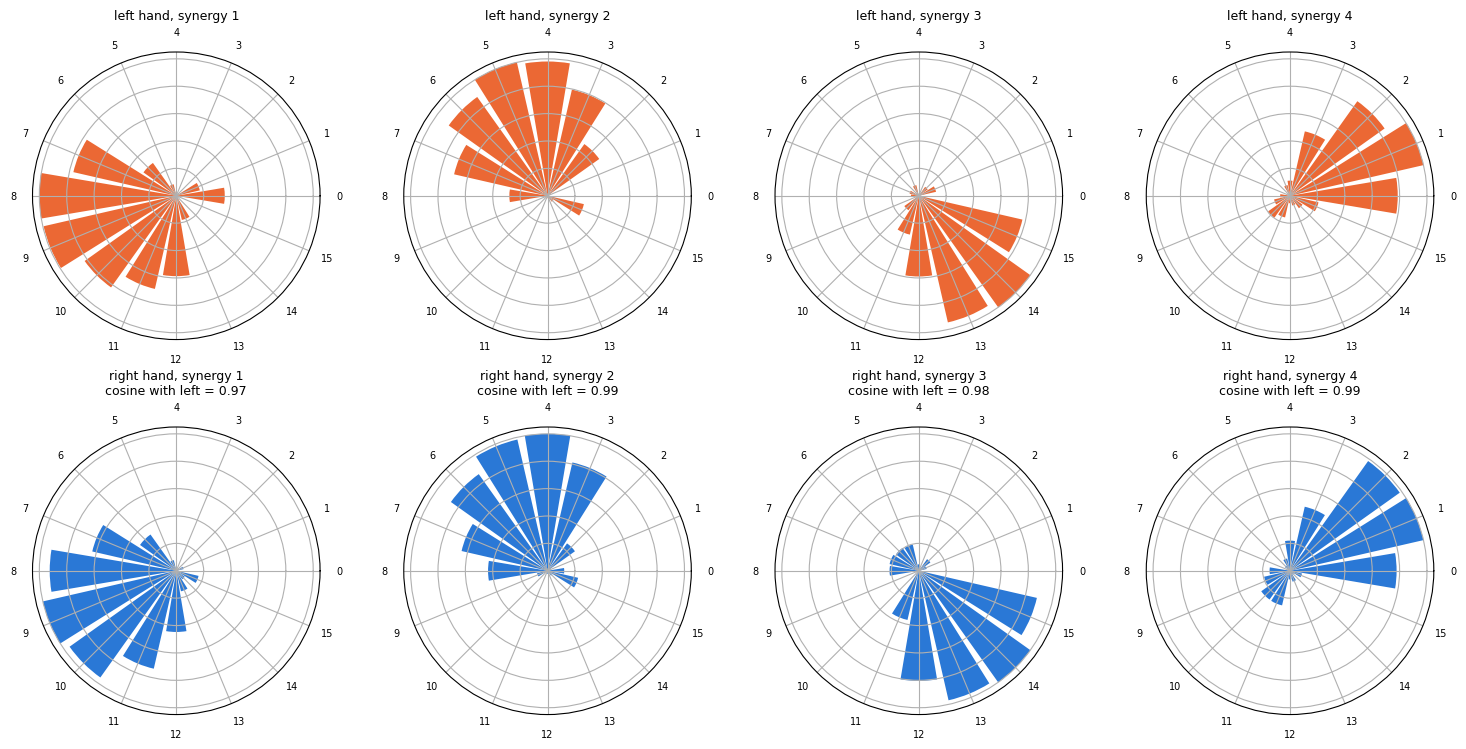

matched cosine similarities: [0.97 0.99 0.98 0.99] (chance level for random non-negative 16-D patterns ≈ 0.75)


In [12]:
syn_hand = {}
for side in ["left", "right"]:
    E = np.vstack([r["lin"][r["ok"]] for r in recs if r["side"] == side])
    E = E / E.std(0)
    Wh = NMF(n_components=4, init="nndsvda", max_iter=800, random_state=0).fit(E).components_
    syn_hand[side] = Wh / np.linalg.norm(Wh, axis=1, keepdims=True)
S = syn_hand["left"] @ syn_hand["right"].T
ri, ci = linear_sum_assignment(-S)
ang_c = 2 * np.pi * np.arange(16) / 16
fig, axs = plt.subplots(2, 4, figsize=(15, 7.5), subplot_kw={"projection": "polar"})
for j, (a, b) in enumerate(zip(ri, ci)):
    for i, (side, idx, col) in enumerate([("left", a, ORANGE), ("right", b, BLUE)]):
        ax = axs[i, j]; w = syn_hand[side][idx]
        ax.bar(ang_c, w / w.max(), width=2 * np.pi / 16 * 0.85, color=col)
        ax.set_xticks(ang_c, [str(c) for c in range(16)], fontsize=7); ax.set_yticklabels([])
        ax.set_title(f"{side} hand, synergy {j + 1}" + (f"\ncosine with left = {S[a, b]:.2f}" if side == "right" else ""), fontsize=9)
plt.tight_layout(); plt.show()
print("matched cosine similarities:", np.round(S[ri, ci], 2), "(chance level for random non-negative 16-D patterns ≈ 0.75)")

A note on that chance level: two random non-negative vectors are never orthogonal, so cosine similarity between
non-negative synergies is high even by chance. A fair baseline comes from shuffling channels: we compute it below.

In [13]:
rng = np.random.default_rng(0)
null = []
for _ in range(500):
    perm = rng.permutation(16)
    Sp = syn_hand["left"] @ syn_hand["right"][:, perm].T
    rr_, cc_ = linear_sum_assignment(-Sp)
    null.append(Sp[rr_, cc_].mean())
print(f"mean matched cosine: observed {S[ri, ci].mean():.2f}; channel-shuffled null {np.mean(null):.2f} "
      f"(95th percentile {np.percentile(null, 95):.2f})")

mean matched cosine: observed 0.98; channel-shuffled null 0.60 (95th percentile 0.69)


## 7. Summary and how we would actually test it

(Numbers from this run; interpretation below.)

In [14]:
print(f"H1 participation ratio: raw signal {pr_raw:.1f} vs envelopes {pr_env:.1f}")
for target, (rr, pc, full) in res.items():
    r90 = next(r for r in RANKS if rr[r] >= 0.9 * full); p90 = next(r for r in RANKS if pc[r] >= 0.9 * full)
    print(f"H2 {target}: rank for 90 % of full R² -> RRR {r90}, PCA bottleneck {p90}")
print(f"H2 equal-weight PCs: rank for 90 % = {r90_eq} of 8")
print("H3 subspace overlap RRR vs PCA:", {r: round(overlap[r], 2) for r in (1, 2, 3, 4, 6, 8)}, "null:", {r: round(overlap_null[r], 2) for r in (1, 2, 3, 4, 6, 8)})
print(f"H4 variance-weighted R², 16 ch vs 5 synergies: {np.average(dec['16 channels'], weights=ev_pose[:8]):.3f} vs "
      f"{np.average(dec['5 muscle synergies'], weights=ev_pose[:8]):.3f}")
print(f"5b EMG variance in 3 pose-potent dims: {100 * frac_pot:.0f} % vs {100 * frac_top:.0f} % in the top-3 EMG PCs; overlap {ov:.2f}")
print(f"H5 VAF on unseen tasks: own {cross.iloc[:, 0].mean():.3f}, transferred {cross.iloc[:, 1].mean():.3f}; "
      f"hands cosine {S[ri, ci].mean():.2f} vs null {np.mean(null):.2f}")

H1 participation ratio: raw signal 7.5 vs envelopes 2.7
H2 position: rank for 90 % of full R² -> RRR 3, PCA bottleneck 4
H2 velocity: rank for 90 % of full R² -> RRR 2, PCA bottleneck 3
H2 equal-weight PCs: rank for 90 % = 6 of 8
H3 subspace overlap RRR vs PCA: {1: 0.98, 2: 0.72, 3: 0.83, 4: 0.88, 6: 0.87, 8: 0.87} null: {1: 0.98, 2: 0.5, 3: 0.46, 4: 0.63, 6: 0.65, 8: 0.8}
H4 variance-weighted R², 16 ch vs 5 synergies: 0.338 vs 0.166
5b EMG variance in 3 pose-potent dims: 7 % vs 84 % in the top-3 EMG PCs; overlap 0.09
H5 VAF on unseen tasks: own 0.949, transferred 0.907; hands cosine 0.98 vs null 0.60


### What the exploration says (one person, so only as a direction)

| | result | verdict |
|---|---|---|
| H1 | envelopes PR ≈ 2.7 vs raw-signal PR ≈ 7.5: activity is co-modulated far beyond crosstalk | **supported**, with caveats: much of it is one global component (overall effort, possibly also slow shared drifts such as electrode contact) |
| H2 | rank 3 keeps 90 % of the linear EMG → position information in degrees; with the 8 pose PCs weighted equally it takes rank 6 | **supported for the benchmark metric** (useful for choosing k), **not as a neural claim** |
| H3 | overlap 0.8-0.9 with the top pose PCs, but a null input already reaches 0.5-0.98 | **not informative as tested** (needs whitened units and a null distribution) |
| H4 | 5 NMF synergies keep only half of the pose information | **not supported**: the dominant muscle structure is not all the pose needs |
| 5b | only ~25 % of envelope variance is explained by kinematics, evenly across EMG components | open: co-contraction is plausible but untestable here |
| H5 | synergies transfer to unseen tasks (VAF 0.91 vs 0.95) and are nearly identical on both hands (0.98 vs null 0.60) | consistent with a shared vocabulary, but **anatomy predicts the same** |

**What survives the controls**: muscle activity is strongly co-modulated (H1), but its dominant, low-dimensional
structure (the synergies that explain most of the EMG variance) is **not** where most of the posture information is
(H4, and `network_internals.ipynb` finds the same inside Meta's network). The EMG decodes PC1 (open/close) well and
the other postural synergies weakly but genuinely. For the project, a small k is justified by the degree-based metric;
for neuroscience, the interesting candidate story is this **dissociation between variance-dominant muscle synergies
and posture-encoding dimensions**, to be tested across people.

### How we would actually test it (full dataset)

1. **Pre-register** the hypotheses and the metrics above before touching the full data.
2. **Per user**, recompute H1-H5 on held-out users. A neural-synergy account predicts the same small communication
   rank across people and a pose subspace that is **shared across users**, while EMG patterns differ with anatomy and
   band placement. Measure both: cross-user overlap of pose subspaces vs of EMG subspaces.
3. **Null models for every claim**: crosstalk (raw-signal correlation, as in H1), channel shuffles (as in H5), and
   time-shifted surrogates (shift one hand's or one sector's signals in time to destroy shared drive but keep each
   signal's statistics).
4. **A signature that anatomy cannot produce**: shared neural drive shows up as *coherence* between muscle groups in
   the 8-30 Hz range during steady holds (intermuscular coherence; Farina & Negro 2015). Coherence that groups the
   electrodes the same way as the synergies would be evidence for a neural origin. Crosstalk cannot easily mimic it at
   those frequencies, because the raw signals of different motor units are not synchronised.
5. **Compare against a biomechanical null**: synergies fitted on one task family (e.g. finger individuation) should
   fail on another (whole-hand grasps) if they only reflect task constraints. H5 says they transfer here; the full
   dataset (29 stages, held-out stages) makes this a real test.
6. **Measure alignment properly**: whiten the pose (and EMG) before comparing subspaces, and compare against a null
   distribution from many time shifts. Our first H3 test skipped this and was misleading.
7. **Link back to the project**: report communication rank both in degree units (what the benchmark scores) and with
   equal-weight PCs (what the physiology says).